# FIRMS MODIS hotspot EDA with explicit coverage

A hotspot is a reported pixel, not an incident or burned area. Research labels remain **UTC acquisition-day MODIS C6.1, confidence strictly > 80, all type codes retained**. Complete retrieval does not prove cloud-free observation or absence of ground fire. The BIG mask and 5 km lattice remain candidates pending review.

This notebook uses the shared study configuration and development dates only. It never displays held-out outcome distributions. Install the repository editable (`python -m pip install -e . --no-deps`) to run from either the root or `EDA/`. Acquisition/import instructions and the interval ledger schema are in `docs/firms-refresh.md`.

Run all cells from the top after updating the project. The setup cell reloads the local FIRMS importer so an existing kernel uses the current CSV handling.

Active split: **train 2020–2024, test 2025**. Ordinary EDA shows training dates only; 2026 is outside the study. The 2025 file remains registered for separate test preparation.


In [1]:
import json
import os
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from peatguard.study import find_root, load_study
# Refresh local importer changes when rerunning in an existing notebook kernel.
import importlib
import peatguard.firms as firms
importlib.reload(firms)
from peatguard.firms import PRODUCT, ingest, labels, load_spatial, plot_eda, read_ledger, sha256

ROOT = find_root()
# Set PEATGUARD_AS_OF to reproduce a frozen snapshot; no notebook rewrites needed.
study = load_study(root=ROOT, profile=os.getenv("PEATGUARD_PROFILE", "expanded"),
                   end=os.getenv("PEATGUARD_END", "latest"), as_of=os.getenv("PEATGUARD_AS_OF"))
development = {d.isoformat() for d in study.development_dates()}
print(json.dumps(study.metadata(), indent=2))


{
  "schema_version": 1,
  "study_id": "ecd7d7818e14dc0b1411",
  "profile": "expanded",
  "as_of": "2026-10-25T23:59:59.999999+00:00",
  "requested": {
    "start": "2020-01-01",
    "end": "2025-12-31",
    "inclusive": true
  },
  "date_convention": "source_day_utc",
  "target": "same_day_modis_detection_confidence_gt_80",
  "splits": {
    "train": [
      "2020-01-01",
      "2024-12-31"
    ],
    "test": [
      "2025-01-01",
      "2025-12-31"
    ]
  },
  "held_out": [
    "test"
  ],
  "final_test_interval_frozen": true,
  "output_directory": "data/interim/builds/expanded/ecd7d7818e14dc0b1411",
  "development_roles": [
    "train"
  ],
  "grid": {
    "status": "candidate_pending_review",
    "cell_size_m": 5000,
    "crs_proj": "+proj=laea +lat_0=0 +lon_0=114 +datum=WGS84 +units=m +no_defs",
    "lattice_origin_m": [
      0,
      0
    ],
    "cell_id_rule": "kp5_c{grid_col}_r{grid_row}",
    "mask_rule": "all_downloaded_BIG_polygons"
  }
}


## Load explicit retrieval evidence, or preview unverified local archives

The local `data/raw/Firms/intervals.json` ledger is used when present. Set `FIRMS_LEDGER` to select a different verified ledger. Public country exports can contribute positives while their geographic completeness remains unverified; unknown coverage cannot authorize negative labels. Without a ledger, local CSVs are imported with **unknown coverage**. The requested study interval below is a validation envelope, not a claim that an archive covers it. First/last detections never define coverage. No data files are changed.


In [2]:
default_ledger = ROOT / "data/raw/Firms/intervals.json"
ledger_path = os.getenv("FIRMS_LEDGER") or (str(default_ledger) if default_ledger.exists() else None)
if ledger_path:
    intervals = read_ledger(Path(ledger_path).expanduser(), study)
else:
    source = study.config["sources"]["firms"]
    intervals = []
    for path in sorted((ROOT / source["directory"]).glob(source["pattern"])):
        # Automatically preview legacy archives only. API CSVs need their own ledger.
        if not path.name.startswith("fire_archive_"):
            continue
        intervals.append(dict(product=PRODUCT, stage="SP", status="unknown",
            start=str(study.start), end=str(study.end), bbox=[-180,-90,180,90],
            path=str(path), sha256=sha256(path), retrieved_at=study.as_of.isoformat(),
            provenance="Existing legacy archive; export interval and retrieval time unverified: " + path.name))
    print("Archive preview only: all retrieval coverage is unknown; no absence labels authorized.")
all_detections, validated_intervals, ingestion_report = ingest(intervals)
detections = all_detections.loc[all_detections.acq_date.isin(development)].copy() if not all_detections.empty else all_detections
print(json.dumps(ingestion_report, indent=2))
print("Development detections:", len(detections))


{
  "imports": [
    {
      "provenance": "Legacy archive preview only; export date/bounds and true retrieval time unknown; timestamp below is audit time; dates/bbox are row-validation envelope, not coverage proof.",
      "input_rows": 47686,
      "rejected_rows": 0,
      "rejection_reasons": {}
    },
    {
      "provenance": "NASA public country/year file for Indonesia 2025; temporal identity documented by provider listing; country boundary versus BIG mask coverage not verified. Timestamp is acquisition audit; bbox is row-validation envelope only.",
      "input_rows": 17847,
      "rejected_rows": 0,
      "rejection_reasons": {}
    }
  ],
  "input_rows": 65533,
  "rejected_rows": 0,
  "nrt_rows_replaced_by_complete_sp": 0,
  "sp_rows_replaced_by_newer_complete_sp": 0,
  "duplicate_rows_removed": 0,
  "changed_record_groups": 0,
  "retained_rows": 65533
}
Development detections: 47686


## Available source files: training and 2025 test

The table includes test-year file availability. The plots below still use training dates only. File presence and recorded source coverage do not establish complete model-label coverage.

In [3]:
source_availability = pd.DataFrame([
    {"start": item["start"], "end": item["end"],
     "role": ", ".join(role for role, (start, end) in study.profile_config["splits"].items()
                        if item["start"] <= end and item["end"] >= start),
     "file": str(Path(item["path"]).relative_to(ROOT)) if Path(item["path"]).is_relative_to(ROOT) else item["path"],
     "file_present": Path(item["path"]).is_file(),
     "retrieval_coverage": item["status"]}
    for item in intervals if item.get("path")
])
print("2025 is registered as TEST data; training summaries below stop at 2024.")
display(source_availability)


2025 is registered as TEST data; training summaries below stop at 2024.


,start,end,role,file,file_present,retrieval_coverage
0,2020-01-01,2024-12-31,train,data/raw/Firms/DL_FIRE_M-C61_814923/fire_archi...,True,unknown
1,2025-01-01,2025-12-31,test,data/raw/Firms/refresh-2026-10-25/modis_2025_I...,True,unknown


## Source fields and actual development dates

Original rows, acquisition time (including leading zeroes), satellite, collection/version, processing stage, type, and source provenance are retained. Standard-processing complete intervals replace NRT records in the same date/bbox scope, including NRT records no longer present in the corrected export. Exact conservative identities then retain the newest retrieved row. Separate satellites and acquisition minutes survive.


In [4]:
if not detections.empty:
    print("Actual detection dates:", detections.acq_date.min(), "through", detections.acq_date.max())
    for field in ["satellite", "instrument", "version", "stage", "type"]:
        print("\n", field, "\n", detections[field].value_counts(dropna=False).to_string())
    display(detections.head())
else:
    print("No development detections available in this snapshot.")


Actual detection dates: 2020-01-01 through 2024-12-30

 satellite 
 satellite
Aqua     36829
Terra    10857

 instrument 
 instrument
MODIS    47686

 version 
 version
61.03    33432
6.03     14254

 stage 
 stage
SP    47686

 type 
 type
0    43997
2     2768
3      921


,acquired_at_utc,satellite,instrument,product,latitude,longitude,acq_date,acq_time,confidence,type,version,stage,provenance,source_sha256,source_row,retrieved_at,original_record,all_import_provenance
0,2020-01-01T14:49:00+00:00,Terra,MODIS,FIRMS_MODIS_C6.1,5.4289,114.7123,2020-01-01,1449,40.0,3,6.03,SP,Legacy archive preview only; export date/bound...,602eafb78fc45f40daee708cc53077225517d75cdf9bb4...,2,2026-10-25T05:58:46.691659+00:00,"{""acq_date"": ""2020-01-01"", ""acq_time"": ""1449"",...","[""Legacy archive preview only; export date/bou..."
1,2020-01-02T03:07:00+00:00,Terra,MODIS,FIRMS_MODIS_C6.1,5.8772,114.2963,2020-01-02,0307,32.0,3,6.03,SP,Legacy archive preview only; export date/bound...,602eafb78fc45f40daee708cc53077225517d75cdf9bb4...,3,2026-10-25T05:58:46.691659+00:00,"{""acq_date"": ""2020-01-02"", ""acq_time"": ""0307"",...","[""Legacy archive preview only; export date/bou..."
2,2020-01-02T03:10:00+00:00,Terra,MODIS,FIRMS_MODIS_C6.1,-2.9786,113.9921,2020-01-02,0310,35.0,0,6.03,SP,Legacy archive preview only; export date/bound...,602eafb78fc45f40daee708cc53077225517d75cdf9bb4...,4,2026-10-25T05:58:46.691659+00:00,"{""acq_date"": ""2020-01-02"", ""acq_time"": ""0310"",...","[""Legacy archive preview only; export date/bou..."
3,2020-01-04T02:57:00+00:00,Terra,MODIS,FIRMS_MODIS_C6.1,-0.4049,116.5285,2020-01-04,0257,74.0,0,6.03,SP,Legacy archive preview only; export date/bound...,602eafb78fc45f40daee708cc53077225517d75cdf9bb4...,5,2026-10-25T05:58:46.691659+00:00,"{""acq_date"": ""2020-01-04"", ""acq_time"": ""0257"",...","[""Legacy archive preview only; export date/bou..."
4,2020-01-04T02:57:00+00:00,Terra,MODIS,FIRMS_MODIS_C6.1,-1.8908,115.8613,2020-01-04,0257,73.0,0,6.03,SP,Legacy archive preview only; export date/bound...,602eafb78fc45f40daee708cc53077225517d75cdf9bb4...,6,2026-10-25T05:58:46.691659+00:00,"{""acq_date"": ""2020-01-04"", ""acq_time"": ""0257"",...","[""Legacy archive preview only; export date/bou..."


Confidence > 80: 9472 / 47686 ; 80 is excluded; no type filter


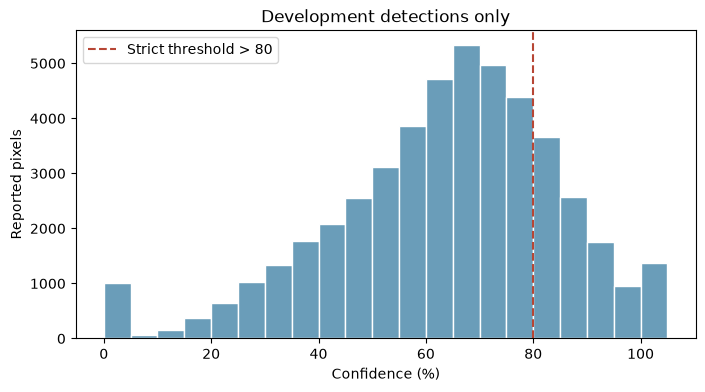

In [5]:
if not detections.empty:
    high = detections.loc[detections.confidence > 80]
    print("Confidence > 80:", len(high), "/", len(detections), "; 80 is excluded; no type filter")
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(detections.confidence, bins=range(0, 106, 5), color="#6a9db9", edgecolor="white")
    ax.axvline(80, color="#b74635", linestyle="--", label="Strict threshold > 80")
    ax.set(xlabel="Confidence (%)", ylabel="Reported pixels", title="Development detections only")
    ax.legend()
    plt.show()


## Candidate lattice labels and honest temporal coverage

Read the existing grid exported by `preprocessing.ipynb`; membership uses the unchanged projected BIG mask, `covers`, and floor division by 5,000 m. An incomplete interval can support an observed positive. It cannot support a negative; unknown labels remain blank. A complete empty interval authorizes zero **reported detections**, not proof of no fire. Recent incomplete UTC days from the fetcher remain unknown.


,cell_days,known_labels
retrieval_coverage,,
unknown,6416424,1009


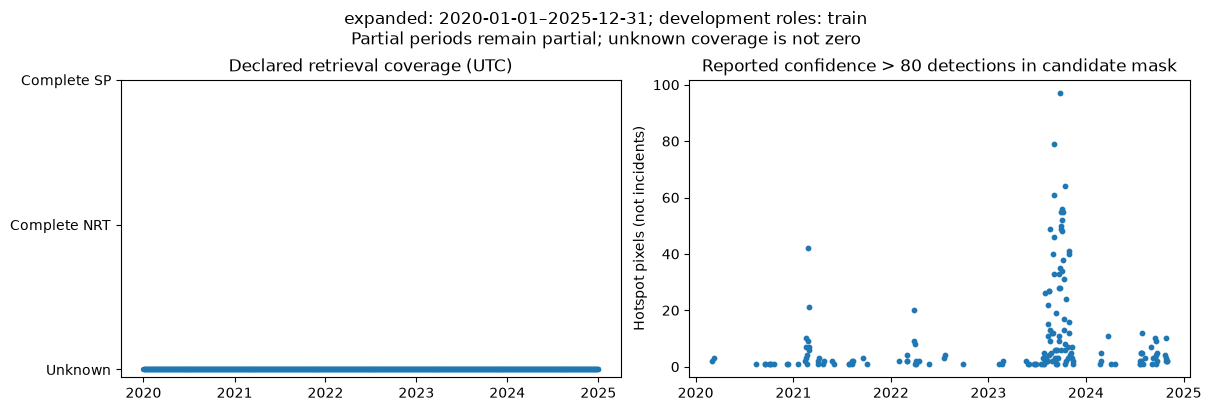

Displayed period is the requested development slice; no annualization or missing-month zero fill.


In [6]:
grid_path = ROOT / "data/interim/study_grid_5km/study_grid_5km.csv"
if grid_path.exists():
    grid, mask, projector, bounds = load_spatial(study, grid_path)
    daily, assigned = labels(study, all_detections, validated_intervals, grid, mask, projector, bounds)
    display(daily.groupby("retrieval_coverage").agg(cell_days=("cell_id", "size"), known_labels=("fire_detected", "count")))
    plot_eda(daily, assigned, study)
    plt.show()
    print("Displayed period is the requested development slice; no annualization or missing-month zero fill.")
else:
    print("Existing candidate lattice not found. Run its spatial preparation before cell labels.")


## What is still unverified

Archive filenames and detection extrema do not establish export coverage. Preserve original export/query confirmations and declare their intervals/bounds before producing negatives. The provider may have missing overpasses or clouds even with a successful query. NRT is provisional and should be refreshed using SP when published. The expanded 2026 test interval is not frozen; this EDA excludes it. These labels describe same-day satellite detections, not future forecasts.
